# K=6 군집의 조정 표준화 잔차(ASR) 추가 분석

Model B의 고정 6군집·5차원 해에 대해 군집과 범주형 변수의 교차표를 복원하고, Haberman 조정 표준화 잔차를 계산한다.

## tl;dr

- 분석 사례는 총 739건이며 군집 크기는 군집 1: 337건, 군집 2: 132건, 군집 3: 97건, 군집 4: 90건, 군집 5: 48건, 군집 6: 35건이다.
- ASR ≥ 1.96인 범주를 상대적 과대표 범주로 보고, 각 군집×변수에서 잔차가 큰 순서로 최대 2개를 선정했다.
- `근본원인별 그룹`은 군집 형성에 사용하지 않은 보조변수다. 나머지 6개 변수는 적극변수이므로 ASR은 독립적인 가설검정이 아니라 군집 프로파일을 요약하는 기술적 지표로 해석해야 한다.

## Context & Methods

원자료와 군집화 과정은 `KAIA_DA_k=6.ipynb`에 기록되어 있다. 이 노트북은 그 노트북의 실행 결과에 완전하게 저장된 범주별 관측빈도를 입력으로 사용한다.

### Key Assumptions

- 군집 번호와 범주별 관측빈도는 제공된 실행 노트북의 Model B K=6 결과를 따른다.
- 범주가 관측되지 않은 군집×범주 조합은 관측빈도 0으로 복원한다.
- 유의 기준은 연구계획에 맞춰 양의 ASR ≥ 1.96으로 고정한다. 다중비교 보정은 적용하지 않으므로 탐색적 프로파일링 결과다.

Haberman 조정 표준화 잔차는 다음과 같다.

$$ASR_{ij}=\frac{O_{ij}-E_{ij}}{\sqrt{E_{ij}(1-p_{i\cdot})(1-p_{\cdot j})}}$$

여기서 $O_{ij}$는 관측빈도, $E_{ij}$는 독립 가정하 기대빈도, $p_{i\cdot}$와 $p_{\cdot j}$는 각각 행·열 주변비율이다.

## Data

### 1. 분석 입력과 무결성 확인

In [1]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

font_path = Path(r'C:\Windows\Fonts\malgun.ttf')
if font_path.exists():
    fm.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = fm.FontProperties(fname=str(font_path)).get_name()
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='white', font=plt.rcParams.get('font.family', ['sans-serif'])[0])

OUTPUT_DIR = Path.cwd()
OBSERVED_PATH = OUTPUT_DIR / 'KAIA_DA_k=6_ASR_observed_counts.csv'
observed_long = pd.read_csv(OBSERVED_PATH, encoding='utf-8-sig')
observed_long['cluster'] = observed_long['cluster'].astype(int)
observed_long['count'] = observed_long['count'].astype(int)

assert observed_long.groupby('variable')['count'].sum().eq(739).all()
cluster_sizes = (
    observed_long.query("variable == '철도구분'")
    .groupby('cluster')['count'].sum().sort_index()
)
assert cluster_sizes.to_dict() == {1: 337, 2: 132, 3: 97, 4: 90, 5: 48, 6: 35}
display(cluster_sizes.rename('n').to_frame())
display(observed_long.groupby('variable').agg(categories=('category', 'nunique'), n=('count', 'sum')))

,n
cluster,
1,337
2,132
3,97
4,90
5,48
6,35


,categories,n
variable,,
근본원인별 그룹,3,739
근본원인별 원인,20,739
열차종류,5,739
장소유형A,6,739
지연운행 원인,4,739
지연운행 현황,6,739
철도구분,3,739


## Results

### 2. 기대빈도·ASR·연관성 지표 계산

In [2]:
def calculate_asr(observed):
    all_results = []
    tests = []
    for variable, values in observed.groupby('variable', sort=False):
        table = (values.pivot(index='cluster', columns='category', values='count')
                 .fillna(0).astype(int).sort_index())
        chi2, p_value, dof, expected = chi2_contingency(table.to_numpy(), correction=False)
        n = int(table.to_numpy().sum())
        row_totals = table.sum(axis=1).to_numpy(dtype=float)
        col_totals = table.sum(axis=0).to_numpy(dtype=float)
        row_props = row_totals / n
        col_props = col_totals / n
        denominator = np.sqrt(expected * (1-row_props[:, None]) * (1-col_props[None, :]))
        asr = np.divide(table.to_numpy(dtype=float)-expected, denominator,
                        out=np.full_like(expected, np.nan), where=denominator > 0)
        result = pd.DataFrame({
            'variable': variable,
            'cluster': np.repeat(table.index.to_numpy(), len(table.columns)),
            'category': np.tile(table.columns.to_numpy(), len(table.index)),
            'observed': table.to_numpy().ravel(),
            'expected': expected.ravel(),
            'adjusted_residual': asr.ravel(),
            'cluster_share_pct': (table.to_numpy()/row_totals[:, None]*100).ravel(),
            'overall_share_pct': np.tile(col_props*100, len(table.index)),
        })
        result['meets_positive_1_96'] = result['adjusted_residual'] >= 1.96
        result['meets_negative_minus_1_96'] = result['adjusted_residual'] <= -1.96
        all_results.append(result)
        rows, cols = table.shape
        tests.append({
            'variable': variable, 'n': n, 'chi_square': chi2,
            'degrees_freedom': dof, 'p_value': p_value,
            'cramers_v': math.sqrt(chi2/(n*min(rows-1, cols-1))),
            'min_expected': expected.min(),
            'expected_below_5_pct': (expected < 5).mean()*100,
        })
    return pd.concat(all_results, ignore_index=True), pd.DataFrame(tests)

all_cells, chi_square_summary = calculate_asr(observed_long)
display(chi_square_summary.round({'chi_square': 2, 'p_value': 4, 'cramers_v': 3, 'min_expected': 2, 'expected_below_5_pct': 1}))

,variable,n,rows_clusters,categories,chi_square,degrees_freedom,p_value,cramers_v,min_expected,expected_below_5_cells,expected_below_5_pct
0,철도구분,739,6,3,385.88,10,0.0,0.511,10.94,0,0.0
1,열차종류,739,6,5,660.68,20,0.0,0.473,0.95,11,36.7
2,지연운행 현황,739,6,6,2151.95,25,0.0,0.763,1.14,15,41.7
3,지연운행 원인,739,6,4,1033.28,15,0.0,0.683,0.85,8,33.3
4,근본원인별 원인,739,6,20,2354.71,95,0.0,0.798,0.05,96,80.0
5,장소유형A,739,6,6,169.79,25,0.0,0.214,0.99,11,30.6
6,근본원인별 그룹,739,6,3,930.15,10,0.0,0.793,4.55,1,5.6


카이제곱과 Cramér's V는 전체 연관의 크기를 요약한다. 적극변수는 군집 형성에 직접 사용되었으므로, 매우 작은 p값은 독립적인 외부 검증으로 해석하지 않는다. 기대빈도 5 미만 셀이 많은 변수는 개별 잔차를 특히 탐색적으로 읽는다.

### 3. ASR ≥ 1.96 범주 중 군집×변수별 상위 2개 선정

In [3]:
selected_top2 = (
    all_cells.loc[all_cells['adjusted_residual'] >= 1.96]
    .sort_values(['cluster', 'variable', 'adjusted_residual', 'observed'],
                 ascending=[True, True, False, False])
    .groupby(['cluster', 'variable'], sort=False, as_index=False).head(2).copy()
)
selected_top2['rank_within_cluster_variable'] = (
    selected_top2.groupby(['cluster', 'variable']).cumcount() + 1
)
selected_top2 = selected_top2[[
    'cluster', 'variable', 'rank_within_cluster_variable', 'category',
    'observed', 'expected', 'adjusted_residual',
    'cluster_share_pct', 'overall_share_pct'
]]
display(selected_top2.round({'expected': 2, 'adjusted_residual': 2, 'cluster_share_pct': 2, 'overall_share_pct': 2}))

,cluster,variable,rank_within_cluster_variable,category,observed,expected,adjusted_residual,cluster_share_pct,overall_share_pct
264,1,근본원인별 그룹,1,기술적요인,306,243.97,10.25,90.80,72.40
117,1,근본원인별 원인,1,열차차량설비,301,177.85,18.22,89.32,52.77
21,1,열차종류,1,여객열차,312,186.97,18.58,92.58,55.48
22,1,열차종류,2,화물열차,15,9.12,2.68,4.45,2.71
233,1,장소유형A,1,역간,172,146.38,3.82,51.04,43.44
85,1,지연운행 원인,1,지연운행 발생원인-시설장비결함,329,261.30,11.98,97.63,77.54
53,1,지연운행 현황,1,지연운행 발생현황-차량고장,313,190.16,18.30,92.88,56.43
2,1,철도구분,1,일반철도,160,105.34,8.71,47.48,31.26
0,1,철도구분,2,고속철도,172,119.02,8.19,51.04,35.32
267,2,근본원인별 그룹,1,기술적요인,121,95.56,5.46,91.67,72.40


### 4. 변수별 ASR 히트맵

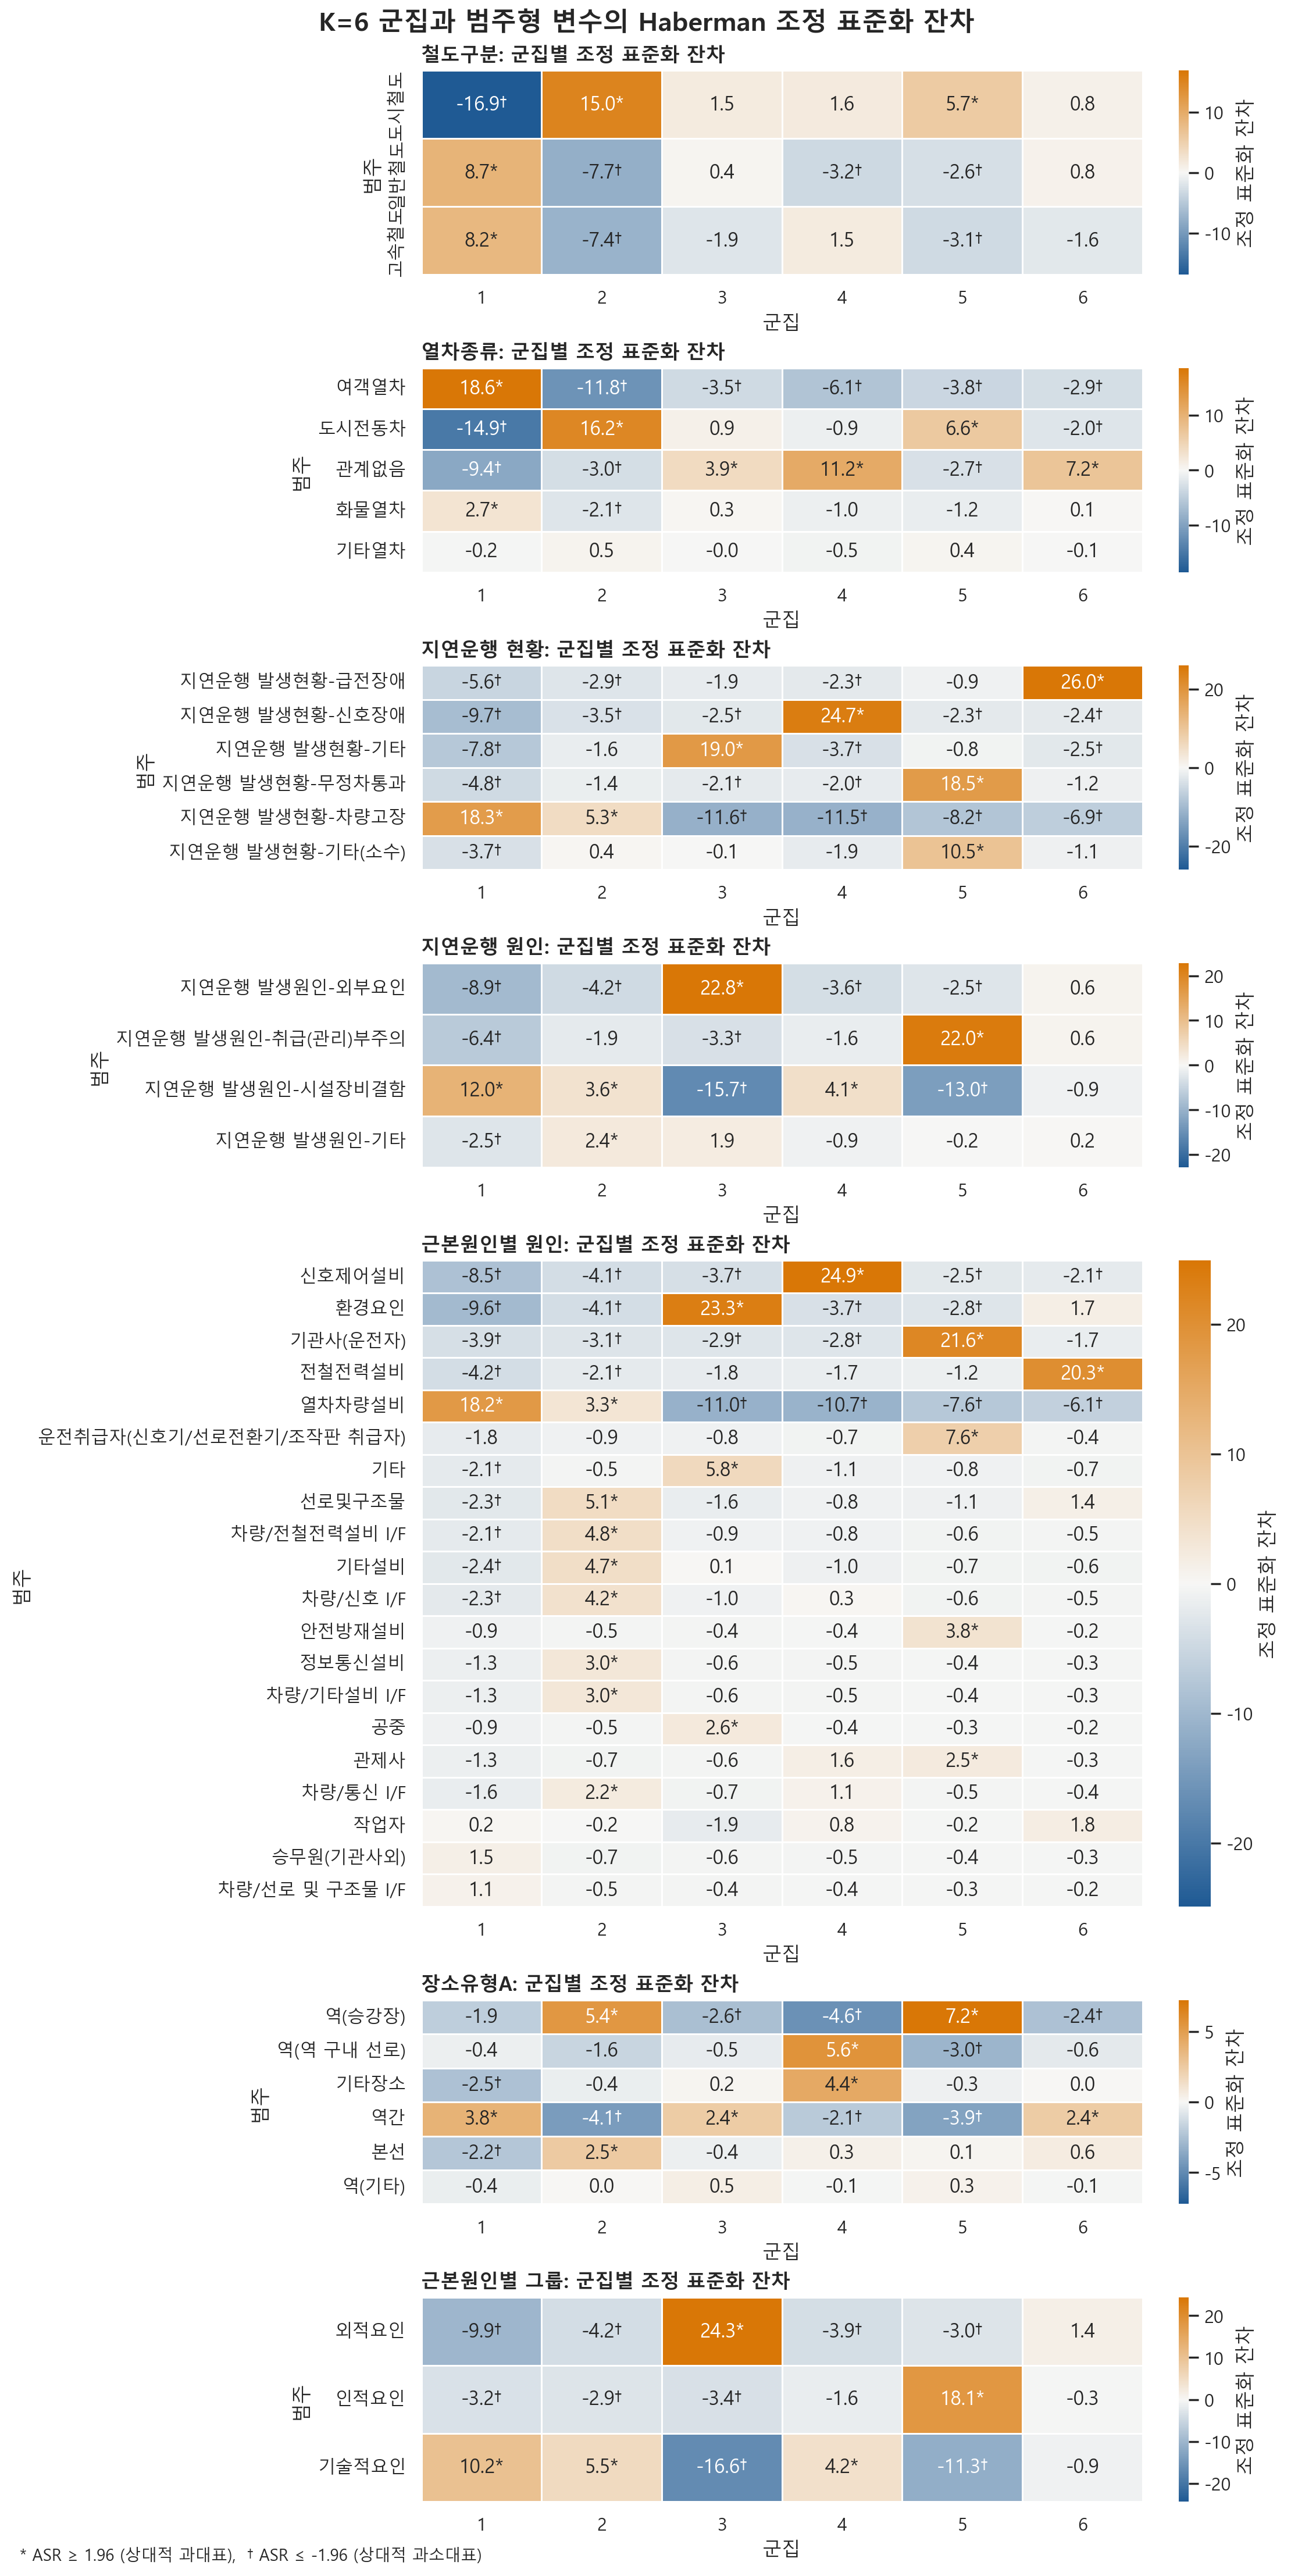

In [4]:
cmap = LinearSegmentedColormap.from_list('navy_white_gold', ['#1F5A94', '#F7F7F5', '#D97706'])
variables = observed_long['variable'].drop_duplicates().tolist()
category_counts = all_cells.groupby('variable')['category'].nunique().reindex(variables)
height_ratios = [max(2.4, 0.38*n) for n in category_counts]
fig, axes = plt.subplots(len(variables), 1, figsize=(11, sum(height_ratios)),
                         gridspec_kw={'height_ratios': height_ratios}, constrained_layout=True)
for ax, variable in zip(axes, variables):
    subset = all_cells.query('variable == @variable')
    matrix = subset.pivot(index='category', columns='cluster', values='adjusted_residual')
    ordering = matrix.max(axis=1).sort_values(ascending=False).index
    matrix = matrix.loc[ordering]
    max_abs = np.nanmax(np.abs(matrix.to_numpy()))
    annotations = matrix.map(lambda value: f'{value:.1f}' + ('*' if value >= 1.96 else ('†' if value <= -1.96 else '')))
    sns.heatmap(matrix, ax=ax, cmap=cmap, center=0, vmin=-max_abs, vmax=max_abs,
                annot=annotations, fmt='', linewidths=0.5, linecolor='white',
                cbar_kws={'label': '조정 표준화 잔차'})
    ax.set_title(f'{variable}: 군집별 조정 표준화 잔차', loc='left', fontsize=12, weight='bold')
    ax.set_xlabel('군집')
    ax.set_ylabel('범주')
fig.suptitle('K=6 군집과 범주형 변수의 Haberman 조정 표준화 잔차', fontsize=16, weight='bold')
fig.text(0.01, 0.002, '* ASR ≥ 1.96 (상대적 과대표),  † ASR ≤ -1.96 (상대적 과소대표)', fontsize=10)
plt.savefig('KAIA_DA_k=6_ASR_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

### 5. 군집별 선정 특성 요약

In [5]:
summary_rows = []
for cluster, values in selected_top2.groupby('cluster', sort=True):
    parts = []
    for variable, subset in values.groupby('variable', sort=False):
        cats = ', '.join(f"{r.category} (ASR {r.adjusted_residual:.2f})" for r in subset.itertuples())
        parts.append(f'{variable}: {cats}')
    summary_rows.append({'cluster': int(cluster), 'selected_characteristics': ' | '.join(parts)})
cluster_summary = pd.DataFrame(summary_rows)
display(cluster_summary.style.set_properties(subset=['selected_characteristics'], **{'text-align': 'left'}))

,cluster,selected_characteristics
0,1,"근본원인별 그룹: 기술적요인 (ASR 10.25) | 근본원인별 원인: 열차차량설비 (ASR 18.22) | 열차종류: 여객열차 (ASR 18.58), 화물열차 (ASR 2.68) | 장소유형A: 역간 (ASR 3.82) | 지연운행 원인: 지연운행 발생원인-시설장비결함 (ASR 11.98) | 지연운행 현황: 지연운행 발생현황-차량고장 (ASR 18.30) | 철도구분: 일반철도 (ASR 8.71), 고속철도 (ASR 8.19)"
1,2,"근본원인별 그룹: 기술적요인 (ASR 5.46) | 근본원인별 원인: 선로및구조물 (ASR 5.10), 차량/전철전력설비 I/F (ASR 4.81) | 열차종류: 도시전동차 (ASR 16.23) | 장소유형A: 역(승강장) (ASR 5.37), 본선 (ASR 2.51) | 지연운행 원인: 지연운행 발생원인-시설장비결함 (ASR 3.60), 지연운행 발생원인-기타 (ASR 2.36) | 지연운행 현황: 지연운행 발생현황-차량고장 (ASR 5.33) | 철도구분: 도시철도 (ASR 15.04)"
2,3,"근본원인별 그룹: 외적요인 (ASR 24.31) | 근본원인별 원인: 환경요인 (ASR 23.35), 기타 (ASR 5.78) | 열차종류: 관계없음 (ASR 3.93) | 장소유형A: 역간 (ASR 2.39) | 지연운행 원인: 지연운행 발생원인-외부요인 (ASR 22.81) | 지연운행 현황: 지연운행 발생현황-기타 (ASR 18.98)"
3,4,"근본원인별 그룹: 기술적요인 (ASR 4.24) | 근본원인별 원인: 신호제어설비 (ASR 24.89) | 열차종류: 관계없음 (ASR 11.17) | 장소유형A: 역(역 구내 선로) (ASR 5.64), 기타장소 (ASR 4.36) | 지연운행 원인: 지연운행 발생원인-시설장비결함 (ASR 4.10) | 지연운행 현황: 지연운행 발생현황-신호장애 (ASR 24.71)"
4,5,"근본원인별 그룹: 인적요인 (ASR 18.10) | 근본원인별 원인: 기관사(운전자) (ASR 21.60), 운전취급자(신호기/선로전환기/조작판 취급자) (ASR 7.61) | 열차종류: 도시전동차 (ASR 6.58) | 장소유형A: 역(승강장) (ASR 7.23) | 지연운행 원인: 지연운행 발생원인-취급(관리)부주의 (ASR 22.02) | 지연운행 현황: 지연운행 발생현황-무정차통과 (ASR 18.49), 지연운행 발생현황-기타(소수) (ASR 10.48) | 철도구분: 도시철도 (ASR 5.68)"
5,6,근본원인별 원인: 전철전력설비 (ASR 20.33) | 열차종류: 관계없음 (ASR 7.16) | 장소유형A: 역간 (ASR 2.37) | 지연운행 현황: 지연운행 발생현황-급전장애 (ASR 25.98)


## Takeaways

- 군집 1은 여객열차·차량고장·열차차량설비를 중심으로 한 차량설비형이다.
- 군집 2는 도시철도·도시전동차가 과대표되는 도시전동차 차량고장형이다.
- 군집 3은 외부요인·환경요인이 집중되는 외적 환경요인형이다.
- 군집 4는 신호장애·신호제어설비가 집중되는 신호설비형이다.
- 군집 5는 취급(관리)부주의·기관사(운전자)·무정차통과가 집중되는 인적 취급오류형이다.
- 군집 6은 급전장애·전철전력설비가 집중되는 전철전력형이다.

`근본원인별 그룹`에서 군집 3의 외적요인과 군집 5의 인적요인은 군집 형성에 사용하지 않은 보조변수에서 확인된 특성이므로 해석상 특히 유용하다.